# ModernBERT + Attention Pooling — IMDb Sentiment Analysis

Sentiment analysis of IMDb movie reviews (50,000 reviews, columns `review` and `sentiment`) with **ModernBERT-base** and an attention-pooling classification head (no BiLSTM). Simpler and faster than the paper's RoBERTa-BiLSTM.

**Pipeline:** Review text → light preprocessing → ModernBERT → [CLS] + Attention pooling → Dense → Softmax → Positive/Negative

This notebook will: upload and inspect the IMDb CSV, create labels, split the data, tokenize, train the model, evaluate it (accuracy, precision, recall, F1), draw a confusion matrix, **predict the sentiment of your own reviews**, and save the trained model.

It is designed for Google Colab with a GPU: `Runtime → Change runtime type → GPU`, then `Runtime → Run all`.

## 1. Check GPU

In [1]:
import torch
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("GPU is not available. In Colab select Runtime > Change runtime type > GPU.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 2. Install required libraries

In [2]:
!pip install -q "transformers>=4.48" accelerate sentencepiece tiktoken

## 3. Import libraries

In [3]:
import os, re, gc, json, time, math, random
from functools import partial

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/imdb_modernbert'
os.makedirs(SAVE_DIR, exist_ok=True)

Mounted at /content/drive


## 4. Project settings

* `MAX_LENGTH` – maximum tokens per review. IMDb reviews are long (average ≈ 300 tokens), so 512 keeps most of the text.
* `HEAD_TOKENS` – if a review is longer than `MAX_LENGTH`, we keep its **first** `HEAD_TOKENS` tokens and its **last** tokens (reviews often end with the verdict).
* Two learning rates: a small one for the pretrained encoder, a larger one for the new layers on top.
* `EPOCHS` – 3 is normally enough for IMDb. More epochs mostly cause overfitting.
* If you run out of GPU memory, lower `MAX_LENGTH` to 384 or `BATCH_SIZE` to 8.

In [6]:
MODEL_NAME = "answerdotai/ModernBERT-base"
MODEL_TAG = "modernbert_attnpool"
MODEL_TITLE = "ModernBERT + Attention Pooling"

MAX_LENGTH = 512
HEAD_TOKENS = 128
BATCH_SIZE = 16
ACCUM_STEPS = 2            # effective batch size = 16 x 2 = 32
EPOCHS = 3
LR_ENC = 3e-5              # learning rate of the pretrained encoder
LR_HEAD = 2e-4             # learning rate of the new layers
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.06
DROPOUT_RATE = 0.1
LSTM_HIDDEN_SIZE = 256
SEED = 42                  # same seed in both notebooks -> identical train/val/test split

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

device = torch.device("cuda")
use_bf16 = torch.cuda.get_device_capability()[0] >= 8      # A100/L4 -> bf16, T4 -> fp16
AMP_DTYPE = torch.bfloat16 if use_bf16 else torch.float16
use_scaler = not use_bf16

print("Device:", torch.cuda.get_device_name(0), "| mixed precision:", AMP_DTYPE)
print("Model:", MODEL_NAME)
print("Max sequence length:", MAX_LENGTH, "| Batch size:", BATCH_SIZE, "x", ACCUM_STEPS)
print("Learning rates (encoder / head):", LR_ENC, "/", LR_HEAD)
print("Epochs:", EPOCHS)

Device: Tesla T4 | mixed precision: torch.float16
Model: answerdotai/ModernBERT-base
Max sequence length: 512 | Batch size: 16 x 2
Learning rates (encoder / head): 3e-05 / 0.0002
Epochs: 3


## 5. Upload the IMDb CSV

In [7]:
CANDIDATES = [f"{SAVE_DIR}/IMDB Dataset.csv", "IMDB Dataset.csv", "/content/IMDB Dataset.csv"]
FILE_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)

if FILE_PATH is None:
    from google.colab import files
    uploaded = files.upload()
    csv_files = [n for n in uploaded.keys() if n.lower().endswith(".csv")]
    if not csv_files:
        raise FileNotFoundError("Please upload the IMDb CSV file (columns: review, sentiment).")
    FILE_PATH = csv_files[0]
print("Using file:", FILE_PATH)

Using file: /content/drive/MyDrive/imdb_modernbert/IMDB Dataset.csv


## 6. Load and inspect the dataset

In [8]:
df = pd.read_csv(FILE_PATH)
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())
print("Exact duplicate reviews:", df.duplicated("review").sum())

Dataset shape: (50000, 2)

Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Missing values:


,0
review,0
sentiment,0


Exact duplicate reviews: 418


## 7. Create sentiment labels and check the class distribution

The IMDb file already has text labels, which we convert to numbers:

* `negative` → **0**
* `positive` → **1**

We also drop exact **duplicate reviews**. IMDb contains a few hundred, and if the same review appeared in both the training and test set the accuracy would be unfairly inflated.

Rows: 50000 -> 49582 after removing duplicates
sentiment_label
Positive    24884
Negative    24698
Name: count, dtype: int64


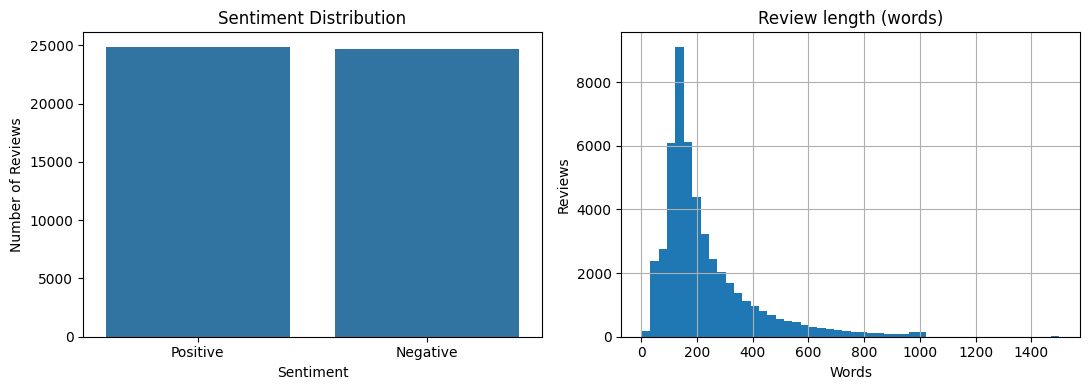

Average length: 231 words


In [9]:
df = df[["review", "sentiment"]].dropna().copy()
n_before = len(df)
df = df.drop_duplicates("review").reset_index(drop=True)
print(f"Rows: {n_before} -> {len(df)} after removing duplicates")

df["label"] = (df["sentiment"].str.lower().str.strip() == "positive").astype(int)
df["sentiment_label"] = df["label"].map({0: "Negative", 1: "Positive"})
print(df["sentiment_label"].value_counts())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="sentiment_label", ax=ax[0])
ax[0].set_title("Sentiment Distribution"); ax[0].set_xlabel("Sentiment"); ax[0].set_ylabel("Number of Reviews")
df["review"].str.split().str.len().clip(upper=1500).hist(bins=50, ax=ax[1])
ax[1].set_title("Review length (words)"); ax[1].set_xlabel("Words"); ax[1].set_ylabel("Reviews")
plt.tight_layout(); plt.show()
print("Average length: %.0f words" % df["review"].str.split().str.len().mean())

## 8. Text preprocessing

We only do **light cleaning**: remove the HTML tags (`<br />`) and extra spaces. We deliberately do *not* lowercase, remove punctuation or remove stop-words, because the pretrained model learned from natural text and words like "not", "!" or capital letters carry sentiment.

In [10]:
def preprocess_text(text):
    text = re.sub(r"<br\s*/?>", " ", str(text))
    return re.sub(r"\s+", " ", text).strip()

example = df["review"].iloc[1]
print("Original:\n", example[:400])
print("\nPreprocessed:\n", preprocess_text(example)[:400])

df["clean_text"] = df["review"].apply(preprocess_text)
df = df[df["clean_text"] != ""].reset_index(drop=True)
print("\nFinal usable samples:", len(df))

Original:
 A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the referen

Preprocessed:
 A wonderful little production. The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary e

Final usable samples: 49582


## 9. Train / validation / test split

* **Train (80%)** – the model learns from this.
* **Validation (10%)** – checked after every epoch to keep the best version of the model.
* **Test (10%)** – used **once at the end** to measure the final accuracy.

The split is *stratified* (each part keeps the 50/50 class balance) and uses a fixed seed. **Both notebooks use the same seed and split, so the two models are tested on exactly the same reviews.**

In [11]:
train_df, temp_df = train_test_split(df, test_size=0.20, random_state=SEED, stratify=df["label"])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"])
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

print("Training samples  :", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples   :", len(test_df))

Training samples  : 39665
Validation samples: 4958
Testing samples   : 4959


## 10. Tokenization, dataset and DataLoader

The tokenizer converts text into token IDs the model understands. Each batch is padded only to the longest review *in that batch*, which is much faster than padding everything to the maximum length.

In [12]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.model_max_length = 10**6        # we truncate ourselves (head + tail)
PAD_ID = tokenizer.pad_token_id
print("Tokenizer loaded:", MODEL_NAME)

def encode_texts(texts):
    raw = tokenizer(list(texts), add_special_tokens=False, truncation=False)["input_ids"]
    budget = MAX_LENGTH - 2                         # room for [CLS] and [SEP]
    out = []
    for ids in raw:
        if len(ids) > budget:
            ids = ids[:HEAD_TOKENS] + ids[-(budget - HEAD_TOKENS):]
        out.append([tokenizer.cls_token_id] + ids + [tokenizer.sep_token_id])
    return out

def pad_batch(seqs):
    L = max(len(s) for s in seqs)
    ids = torch.full((len(seqs), L), PAD_ID, dtype=torch.long)
    mask = torch.zeros((len(seqs), L), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, :len(s)] = torch.tensor(s)
        mask[i, :len(s)] = 1
    return ids, mask

class IMDbDataset(Dataset):
    def __init__(self, token_ids, labels):
        self.token_ids, self.labels = token_ids, labels
    def __len__(self):
        return len(self.token_ids)
    def __getitem__(self, i):
        return self.token_ids[i], int(self.labels[i])

def collate(batch):
    ids, mask = pad_batch([b[0] for b in batch])
    return ids, mask, torch.tensor([b[1] for b in batch])

train_ids = encode_texts(train_df["clean_text"])
val_ids   = encode_texts(val_df["clean_text"])
test_ids  = encode_texts(test_df["clean_text"])
y_train, y_val, y_test = train_df["label"].values, val_df["label"].values, test_df["label"].values
print("Average tokens per training review: %.0f" % np.mean([len(x) for x in train_ids]))

train_loader = DataLoader(IMDbDataset(train_ids, y_train), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
print("DataLoader ready!")

config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.13M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

Tokenizer loaded: answerdotai/ModernBERT-base
Average tokens per training review: 262
DataLoader ready!


## 11. Build the ModernBERT + Attention Pooling model

**Architecture:** ModernBERT → ([CLS] vector + attention-pooled vector) → Dense → Softmax

**Attention pooling** is a small learned layer that scores every word ("how important is this word for the sentiment?") and averages the word vectors using those scores; padding is ignored. The model returns *logits*; softmax is applied when probabilities are needed.

In [13]:
class AttentionPooling(nn.Module):
    """Learns how important each word is, then takes a weighted average of the word vectors."""
    def __init__(self, hidden):
        super().__init__()
        self.score = nn.Sequential(nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, 1))
    def forward(self, x, mask):
        x = x.float()
        scores = self.score(x).squeeze(-1).masked_fill(mask == 0, -1e4)    # ignore padding
        weights = torch.softmax(scores, dim=-1)                            # (batch, length)
        return torch.bmm(weights.unsqueeze(1), x).squeeze(1)               # (batch, hidden)

class ModernBertAttn(nn.Module):
    def __init__(self, model_name, num_classes=2, dropout_rate=0.1):
        super().__init__()
        self.enc = AutoModel.from_pretrained(model_name)
        h = self.enc.config.hidden_size
        self.pool = AttentionPooling(h)
        self.head = nn.Sequential(nn.Dropout(dropout_rate), nn.Linear(2 * h, h), nn.GELU(),
                                  nn.Dropout(dropout_rate), nn.Linear(h, num_classes))
    def forward(self, input_ids, attention_mask):
        out = self.enc(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        features = torch.cat([out[:, 0].float(),                       # [CLS] summary
                              self.pool(out, attention_mask)], dim=-1) # attention-pooled summary
        return self.head(features)                                     # logits

model = ModernBertAttn(MODEL_NAME, num_classes=2, dropout_rate=DROPOUT_RATE).to(device)
print(f"Model created successfully!  Parameters: {sum(p.numel() for p in model.parameters()):,}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model created successfully!  Parameters: 150,787,587


## 12. Training and evaluation functions

* `predict_proba` – returns the probability of each class (Negative / Positive) for a list of tokenized reviews.
* `compute_metrics` – accuracy, precision, recall and F1 (weighted averages).
* Training uses mixed precision (faster, less memory), gradient accumulation, learning-rate warm-up with linear decay, and gradient clipping.

In [14]:
@torch.no_grad()
def predict_proba(model, token_ids, bs=64):
    model.eval()
    order = np.argsort([len(x) for x in token_ids])       # sort by length for speed
    probs = np.zeros((len(token_ids), 2), dtype=np.float32)
    for i in range(0, len(order), bs):
        idx = order[i:i + bs]
        ids, mask = pad_batch([token_ids[j] for j in idx])
        with torch.autocast("cuda", dtype=AMP_DTYPE):
            logits = model(ids.to(device), mask.to(device))
        probs[idx] = torch.softmax(logits.float(), -1).cpu().numpy()
    return probs

def compute_metrics(y_true, probs):
    pred = probs.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y_true, pred, average="weighted", zero_division=0)
    loss = float(-np.log(probs[np.arange(len(y_true)), y_true] + 1e-12).mean())
    return dict(accuracy=accuracy_score(y_true, pred) * 100, precision=p * 100,
                recall=r * 100, f1=f1 * 100, loss=loss)

NO_DECAY = ("bias", "LayerNorm.weight", "layernorm", "norm")
def make_param_groups(named_params, lr):
    decay = [p for n, p in named_params if not any(k in n for k in NO_DECAY)]
    nodecay = [p for n, p in named_params if any(k in n for k in NO_DECAY)]
    return [dict(params=decay, lr=lr, weight_decay=WEIGHT_DECAY),
            dict(params=nodecay, lr=lr, weight_decay=0.0)]

def train_one_epoch(model, loader, opt, sched, scaler, label):
    model.train()
    opt.zero_grad(set_to_none=True)
    total_loss, correct, total = 0.0, 0, 0
    bar = tqdm(loader, desc=label)
    for i, (ids, mask, y) in enumerate(bar):
        ids, mask, y = ids.to(device), mask.to(device), y.to(device)
        with torch.autocast("cuda", dtype=AMP_DTYPE):
            logits = model(ids, mask)
        loss = F.cross_entropy(logits.float(), y)
        scaler.scale(loss / ACCUM_STEPS).backward()
        if (i + 1) % ACCUM_STEPS == 0 or (i + 1) == len(loader):
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            opt.zero_grad(set_to_none=True)
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        total += len(y)
        if i % 50 == 0:
            bar.set_postfix(loss=f"{total_loss/total:.4f}", acc=f"{correct/total*100:.2f}%")
    return total_loss / total, correct / total * 100

print("Training functions ready!")

Training functions ready!


## 13. Train the model

After every epoch the model is checked on the validation set, and the best version is saved. This step takes a while (see the note at the top of the settings).

In [17]:
best_model_path = f"{SAVE_DIR}/best_{MODEL_TAG}_imdb.pth"
ckpt_path = f"{SAVE_DIR}/last_checkpoint.pt"

enc_named  = [(n, p) for n, p in model.named_parameters() if n.startswith("enc.")]
head_named = [(n, p) for n, p in model.named_parameters() if not n.startswith("enc.")]
optimizer = torch.optim.AdamW(make_param_groups(enc_named, LR_ENC) + make_param_groups(head_named, LR_HEAD),
                              betas=(0.9, 0.98), eps=1e-6)
total_steps = math.ceil(len(train_loader) / ACCUM_STEPS) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)

history = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
best_val_accuracy = -1.0
start_epoch = 1

# ---- resume if a checkpoint exists ----
if os.path.exists(ckpt_path):
    ck = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(ck["model"])
    optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"])
    scaler.load_state_dict(ck["scaler"])
    history, best_val_accuracy = ck["history"], ck["best_val"]
    start_epoch = ck["epoch"] + 1
    print(f"Resuming from epoch {start_epoch}")

start = time.time()
for epoch in range(start_epoch, EPOCHS + 1):
    print(f"\n{'='*60}\nEpoch {epoch}/{EPOCHS}\n{'='*60}")
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, scheduler, scaler, f"epoch {epoch}/{EPOCHS}")
    v = compute_metrics(y_val, predict_proba(model, val_ids))

    history["train_loss"].append(train_loss);  history["train_accuracy"].append(train_acc)
    history["val_loss"].append(v["loss"]);     history["val_accuracy"].append(v["accuracy"])
    print(f"Training Loss: {train_loss:.4f} | Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {v['loss']:.4f} | Accuracy: {v['accuracy']:.2f}%")

    if v["accuracy"] > best_val_accuracy:
        best_val_accuracy = v["accuracy"]
        torch.save(model.state_dict(), best_model_path)
        print("✓ Best model saved to Drive.")

    # checkpoint after EVERY epoch (everything needed to resume)
    torch.save({"epoch": epoch, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                "history": history, "best_val": best_val_accuracy}, ckpt_path)

train_minutes = (time.time() - start) / 60


Epoch 1/3


epoch 1/3:   0%|          | 0/2480 [00:00<?, ?it/s]

Training Loss: 0.0960 | Accuracy: 97.02%
Validation Loss: 0.1227 | Accuracy: 96.01%
✓ Best model saved to Drive.

Epoch 2/3


epoch 2/3:   0%|          | 0/2480 [00:00<?, ?it/s]

Training Loss: 0.0406 | Accuracy: 98.98%
Validation Loss: 0.1652 | Accuracy: 96.07%
✓ Best model saved to Drive.

Epoch 3/3


epoch 3/3:   0%|          | 0/2480 [00:00<?, ?it/s]

Training Loss: 0.0099 | Accuracy: 99.79%
Validation Loss: 0.2716 | Accuracy: 95.99%


## 14. Plot training history

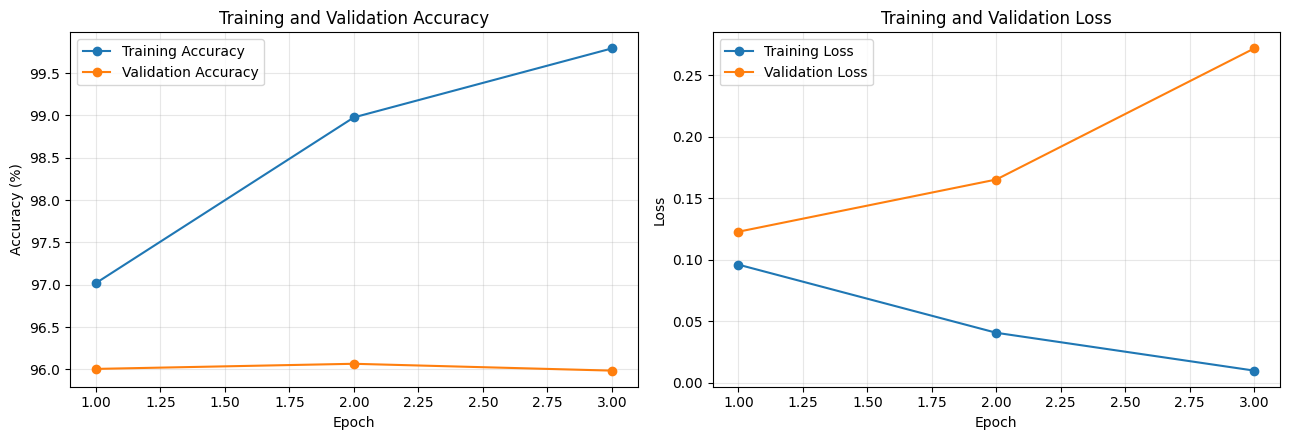

In [28]:
epochs_range = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(epochs_range, history["train_accuracy"], marker="o", label="Training Accuracy")
ax[0].plot(epochs_range, history["val_accuracy"], marker="o", label="Validation Accuracy")
ax[0].set_title("Training and Validation Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy (%)")
ax[1].plot(epochs_range, history["train_loss"], marker="o", label="Training Loss")
ax[1].plot(epochs_range, history["val_loss"], marker="o", label="Validation Loss")
ax[1].set_title("Training and Validation Loss"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss")
for a in ax:
    a.legend(); a.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 15. Final test evaluation

We load the best saved model and evaluate it **once** on the test set, which the model has never seen. This gives the final accuracy of the model.

In [29]:
model.load_state_dict(torch.load(best_model_path, map_location=device))
test_probs = predict_proba(model, test_ids)
test_predictions = test_probs.argmax(1)
m = compute_metrics(y_test, test_probs)

print("=" * 50)
print(f"FINAL TEST RESULTS  ({MODEL_NAME})")
print("=" * 50)
print(f"Test Loss : {m['loss']:.4f}")
print(f"Accuracy  : {m['accuracy']:.2f}%")
print(f"Precision : {m['precision']:.2f}%")
print(f"Recall    : {m['recall']:.2f}%")
print(f"F1 Score  : {m['f1']:.2f}%")
print("\nFor reference, the paper's RoBERTa-BiLSTM on IMDb: Accuracy 92.36% | F1 92.35%")

FINAL TEST RESULTS  (answerdotai/ModernBERT-base)
Test Loss : 0.1673
Accuracy  : 95.93%
Precision : 95.93%
Recall    : 95.93%
F1 Score  : 95.93%

For reference, the paper's RoBERTa-BiLSTM on IMDb: Accuracy 92.36% | F1 92.35%


## 16. Classification report

In [30]:
print(classification_report(y_test, test_predictions, target_names=["Negative", "Positive"], digits=4, zero_division=0))

              precision    recall  f1-score   support

    Negative     0.9562    0.9623    0.9592      2470
    Positive     0.9624    0.9562    0.9593      2489

    accuracy                         0.9593      4959
   macro avg     0.9593    0.9593    0.9593      4959
weighted avg     0.9593    0.9593    0.9593      4959



## 17. Confusion matrix

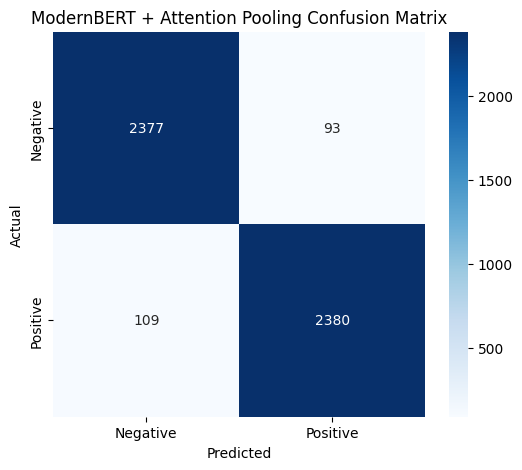

Confusion matrix:
[[2377   93]
 [ 109 2380]]


In [31]:
cm = confusion_matrix(y_test, test_predictions)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"{MODEL_TITLE} Confusion Matrix")
plt.show()
print("Confusion matrix:")
print(cm)

## 18. Predict sentiment for your own reviews

Type any movie review into `predict_sentiment(...)`; the model returns Positive or Negative with its confidence. You can also run this cell again later with new text.

In [32]:
def predict_sentiment(text):
    cleaned = preprocess_text(text)
    ids = encode_texts([cleaned])
    probs = predict_proba(model, ids)[0]
    label = ["Negative", "Positive"][int(probs.argmax())]
    print("Review:")
    print(text)
    print("\nPrediction:", label)
    print("\nProbabilities:")
    print(f"Negative: {probs[0]*100:.2f}%")
    print(f"Positive: {probs[1]*100:.2f}%")
    return label, probs

predict_sentiment("This movie was a masterpiece. The acting was brilliant and the story kept me hooked until the very end.")
print("\n" + "-" * 60 + "\n")
predict_sentiment("A complete waste of time. The plot made no sense and the dialogue was painfully bad.")
print("\n" + "-" * 60 + "\n")
predict_sentiment("I expected much more. Some scenes were nice, but overall it was boring and far too long.")

Review:
This movie was a masterpiece. The acting was brilliant and the story kept me hooked until the very end.

Prediction: Positive

Probabilities:
Negative: 1.93%
Positive: 98.07%

------------------------------------------------------------

Review:
A complete waste of time. The plot made no sense and the dialogue was painfully bad.

Prediction: Negative

Probabilities:
Negative: 99.93%
Positive: 0.07%

------------------------------------------------------------

Review:
I expected much more. Some scenes were nice, but overall it was boring and far too long.

Prediction: Negative

Probabilities:
Negative: 99.90%
Positive: 0.10%


('Negative', array([0.99897975, 0.00102022], dtype=float32))

## 19. Save the trained model and results

In [33]:
final_model_path = f"{SAVE_DIR}/{MODEL_TAG}_imdb_final.pth"
torch.save(model.state_dict(), final_model_path)

results = {
    "model": MODEL_NAME,
    "accuracy": float(m["accuracy"]),
    "precision_weighted": float(m["precision"]),
    "recall_weighted": float(m["recall"]),
    "f1_weighted": float(m["f1"]),
    "test_loss": float(m["loss"]),
    "best_validation_accuracy": float(best_val_accuracy),
    "training_minutes": float(train_minutes),
    "epochs": EPOCHS,
    "max_length": MAX_LENGTH,
    "learning_rate_encoder": LR_ENC,
    "learning_rate_head": LR_HEAD,
    "confusion_matrix": cm.tolist(),
}
results_path = f"{SAVE_DIR}/{MODEL_TAG}_imdb_results.json"
with open(results_path, "w") as f:
    json.dump(results, f, indent=2)

print("Saved model  :", final_model_path)
print("Saved results:", results_path)
print(json.dumps(results, indent=2))

try:
    from google.colab import files
    files.download(results_path)      # the .pth file is large; download it only if you need it
except Exception as e:
    print("Download skipped:", e)

Saved model  : /content/drive/MyDrive/imdb_modernbert/modernbert_attnpool_imdb_final.pth
Saved results: /content/drive/MyDrive/imdb_modernbert/modernbert_attnpool_imdb_results.json
{
  "model": "answerdotai/ModernBERT-base",
  "accuracy": 95.92659810445655,
  "precision_weighted": 95.92861121633074,
  "recall_weighted": 95.92659810445655,
  "f1_weighted": 95.92660605524944,
  "test_loss": 0.1673160046339035,
  "best_validation_accuracy": 96.06696248487293,
  "training_minutes": 93.00700960556667,
  "epochs": 3,
  "max_length": 512,
  "learning_rate_encoder": 3e-05,
  "learning_rate_head": 0.0002,
  "confusion_matrix": [
    [
      2377,
      93
    ],
    [
      109,
      2380
    ]
  ]
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>